# DRVI: a disentangled, per-dimension generative model — `ov.vi.DRVI`

**DRVI** (*Disentangled Representation Variational Inference*; Moinfar &
Theis, ["Disentangling cellular heterogeneity into interpretable biological
factors through structured latent representations"](https://doi.org/10.1101/2024.11.06.622266),
bioRxiv 2024.11.06.622266, and [ICLR 2025 Workshop LMRL](https://openreview.net/forum?id=8FcsvupyOn))
integrates batches like scVI, but its decoder is built so that **every
latent dimension is an independent, additive generator of gene expression**:
each dimension is mapped through its own small linear embedding into the
shared decoder, the same decoder MLP is applied to every dimension on its
own, and the per-dimension outputs are combined with log-sum-exp — the
average contribution in probability space. Ablating one dimension removes
exactly its own contribution to every gene and nothing else, which is what
makes a single latent dimension *interpretable*: a traversal of dimension
*i* alone tells you which genes — and which cell types — that dimension is
"about", without the usual VAE caveat that dimensions interact through a
shared, non-separable decoder.

This is one of the **omicverse batch-correction zoo** tutorials — see
[zoo/index](index.md) for the overview, or [../t_vi](../t_vi.ipynb) for
`ov.vi.SCVI` / `SCANVI` / `TOTALVI`, the scVI-family models that share
DRVI's training machinery (`ov.vi`, pure PyTorch, **no scvi-tools
dependency**).

`ov.vi.DRVI` is a native port of [`drvi-py`](https://github.com/theislab/drvi),
checked for ELBO / disentanglement-score / scib-metrics parity against it
(`benchmarks/vi/results_drvi.md` in the omicverse repo). The interpretability
helpers below (`latent_traverse`, `differential_vars`, `dimension_gene_effects`)
are omicverse's own: they decode the `+`/`-` extremes of one latent
dimension directly, where `drvi-py`'s own traversal utilities rebuild a full
systematic grid through a scvi-tools data loader we do not depend on.


## 1. Data

Bone-marrow mononuclear cells of the NeurIPS 2021 multimodal integration
benchmark (Luecken *et al.*, 2021), gene expression of the CITE-seq arm:
donors `s1d3`, `s2d1`, `s3d7`, profiled at three sites — one batch each —
with the authors' cell-type annotation. Raw counts are stored in
`layers['counts']`; DRVI reads raw counts. Same three donors used by
[../t_vi](../t_vi.ipynb) and by the DRVI validation benchmark
(`benchmarks/vi/results_drvi.md`).


In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()


🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 2
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0
    • [CUDA 1] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata1 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932005', filename='neurips2021_s1d3.h5ad')
adata2 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932008', filename='neurips2021_s2d1.h5ad')
adata3 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932011', filename='neurips2021_s3d7.h5ad')


⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes
⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [3]:
adata = ad.concat([adata1, adata2, adata3], merge='same')
adata.X = adata.layers['counts']
del adata.layers['counts']
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata


AnnData object with n_obs × n_vars = 27423 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: None (.X)

The three donors differ strongly in composition — the situation where
integration must remove the technical donor/site effect without forcing
different cell types together:


In [4]:
pd.crosstab(adata.obs['cell_type'], adata.obs['batch']).sort_values('s1d3', ascending=False).head(8)


batch                 s1d3  s2d1  s3d7
cell_type                             
Reticulocyte           929   270   291
CD8+ T naive           878   312   116
CD4+ T naive           833   883   219
CD4+ T activated       547   690   380
CD14+ Mono             309  2958  6056
NK                     271   282  1242
Naive CD20+ B IGKC+    265   585    88
CD8+ T CD57+ CD45RA+   251    30     0

We also save the raw-count matrix as an `.h5ad` now — it is the input of
the AnnDataOOM (disk-backed) section at the end.


In [5]:
h5ad_path = 'neurips2021_bmmc_counts.h5ad'
adata.write_h5ad(h5ad_path)


## 2. QC and highly variable genes

Loose QC thresholds (the authors already filtered the cells) and 2 000
highly variable genes, matching the DRVI validation benchmark. `ov.pp.preprocess`
keeps the raw counts in `layers['counts']` and flags the HVGs in
`var['highly_variable_features']` — the model selects its training genes
itself (`genes=`), so we do not subset `adata`.


In [6]:
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250}, doublets=False)
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)
adata


🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘

   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range 

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 0.4182s                                                 │
│  Shape:    27,423 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_counts (float)                                     │
│           │ ✚ n_genes (int)                                 


✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 13,953 total (14.3%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 0.70 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

AnnData object with n_obs × n_vars = 26997 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'nUMIs', 'mito_perc', 'ribo_perc', 'hb_perc', 'detected_genes', 'cell_complexity', 'n_counts', 'total_counts', 'n_genes', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'pct_counts_hb', 'passing_mt', 'passing_nUMIs', 'passing_ngenes'
    var: 'feature_types', 'gene_id', 'mt', 'ribo', 'hb', 'n_cells', 'percent_cells', 'robust', 'highly_variable_features', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable'
    uns: 'status', 'status_args', 'REFERENCE_MANU', '_ov_provenance', 'history

## 3. Train `ov.vi.DRVI`

Configuration goes to the constructor, as for every `ov.vi` model. The
defaults left unset below are the paper's own: `n_split_latent=-1` (one
decoder "view" per latent dimension — the setting that makes every
dimension independently decoded), `split_aggregation='logsumexp'`,
`gene_likelihood='pnb'` (`drvi-py`'s own log-mean-parameterised negative
binomial), `dispersion='gene'`. `n_latent=32` matches the DRVI paper and the
validation benchmark exactly, so the numbers below are directly comparable
to `benchmarks/vi/results_drvi.md`.


In [7]:
model = ov.vi.DRVI(adata, layer='counts', batch_key='batch', genes='highly_variable_features',
                   n_latent=32)
model


DRVI(n_obs=26997, n_vars=2000, n_batch=3, n_labels=1, layer='counts', trained=False)

In [8]:
with ov.vi.MemoryMonitor() as mon_mem:
    model.train(max_epochs=100, batch_size=128, check_val_every_n_epoch=10)
mon_mem


Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

MemoryMonitor(wall 27.0 s, RSS 2.14 -> peak 2.98 GB (+0.84), GPU used peak 2.10 GB)

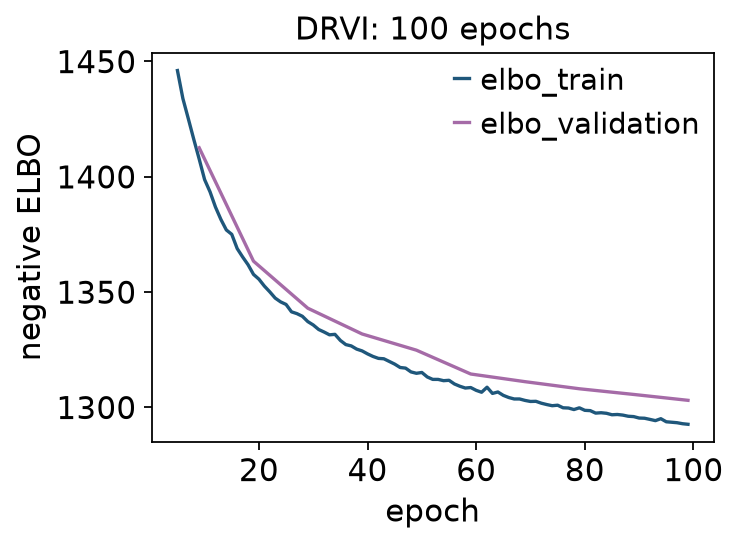

In [9]:
ov.vi.plot_history(model, skip_first=5);


### Latent space

The posterior mean of `z` per cell, a 2-D MDE of it, and — for reference —
the uncorrected PCA of the scaled HVGs:


In [10]:
adata.obsm['X_drvi'] = model.get_latent_representation()
adata.obsm['X_mde_drvi'] = ov.vi.mde(adata.obsm['X_drvi'])
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)
adata.obsm['X_mde_pca'] = ov.vi.mde(adata.obsm['X_pca'])



╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.2101s                                                 │
│  Shape:    26,997 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 26997x13953)                          │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30


   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (26997, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (2.13s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 2.1568s                                                 │
│  Shape:    26,997 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 26997x30)                              │
│           │ ✚ scaled|original|X_pca (array, 26997x30)              │
│         

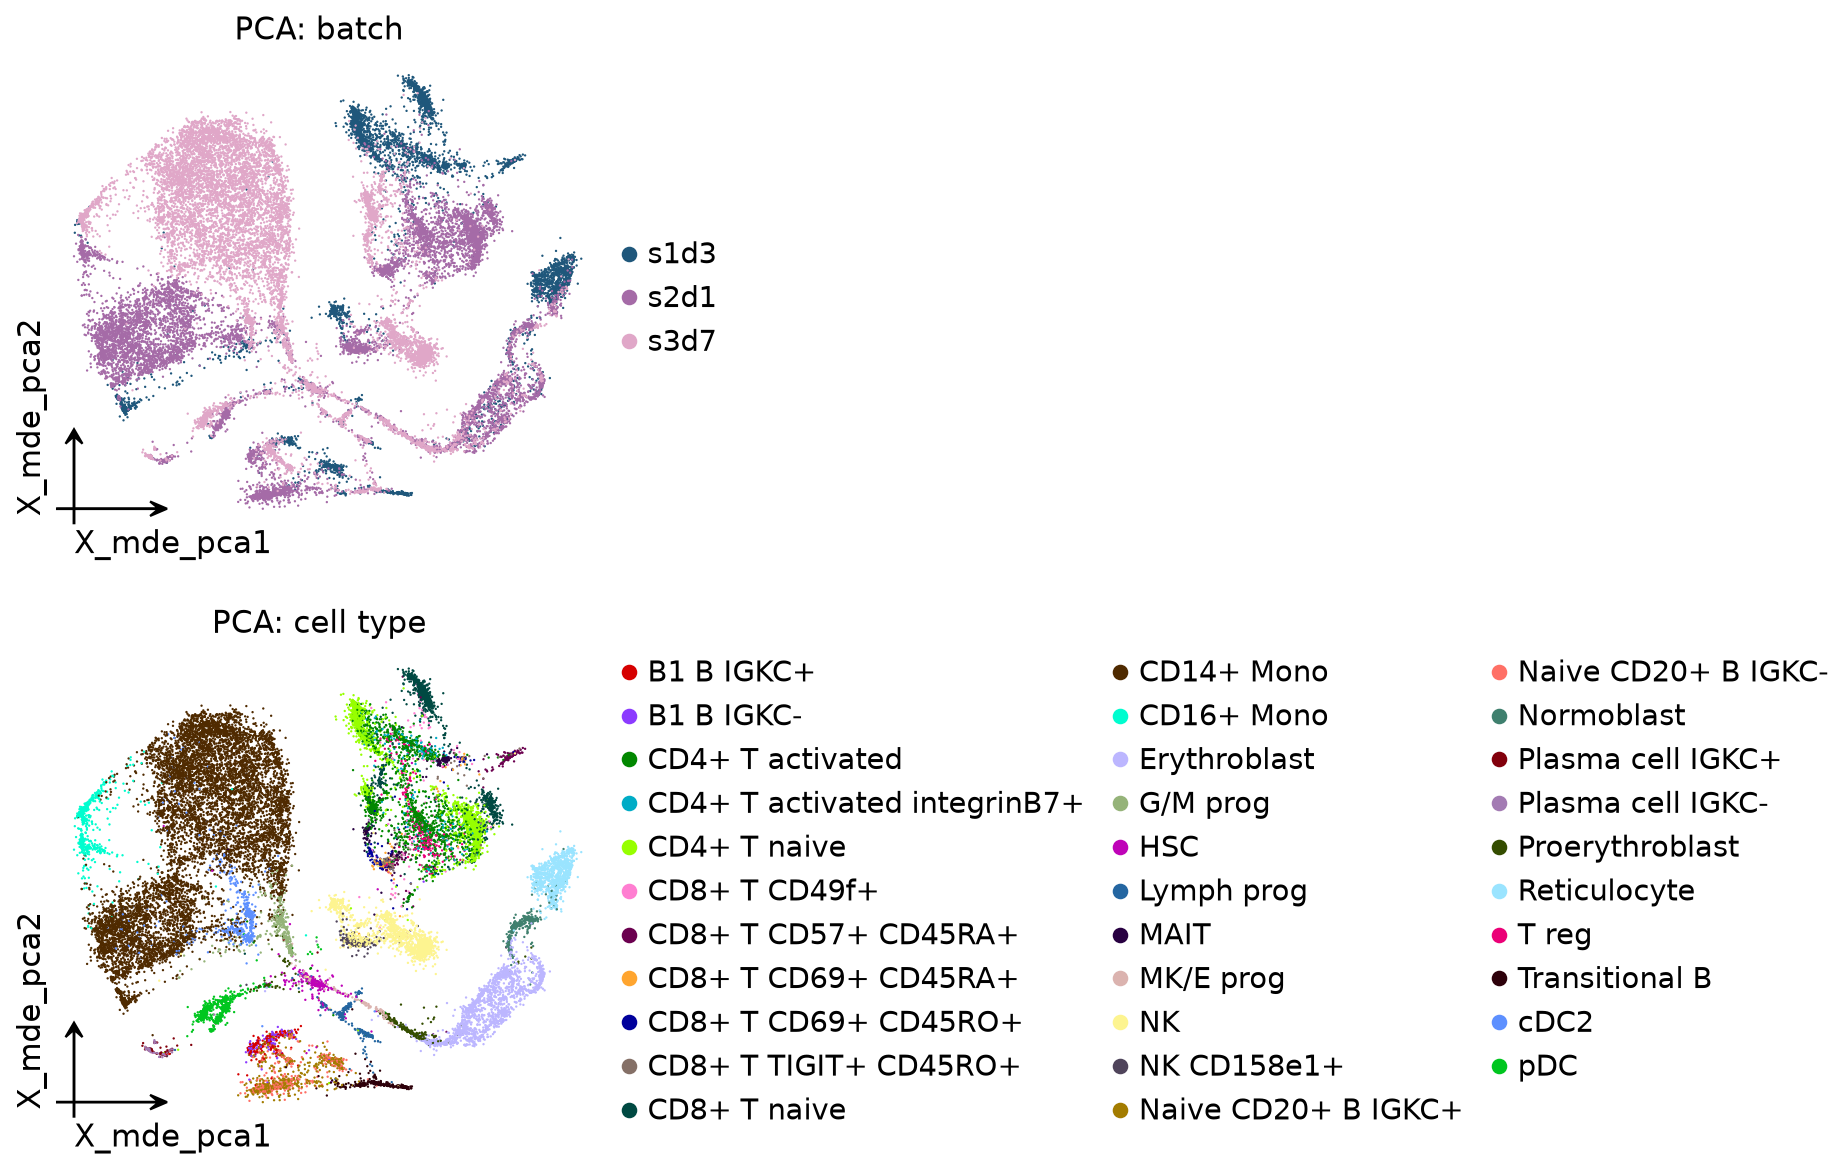

In [11]:
ov.pl.embedding(adata, basis='X_mde_pca', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65, title=['PCA: batch', 'PCA: cell type'])


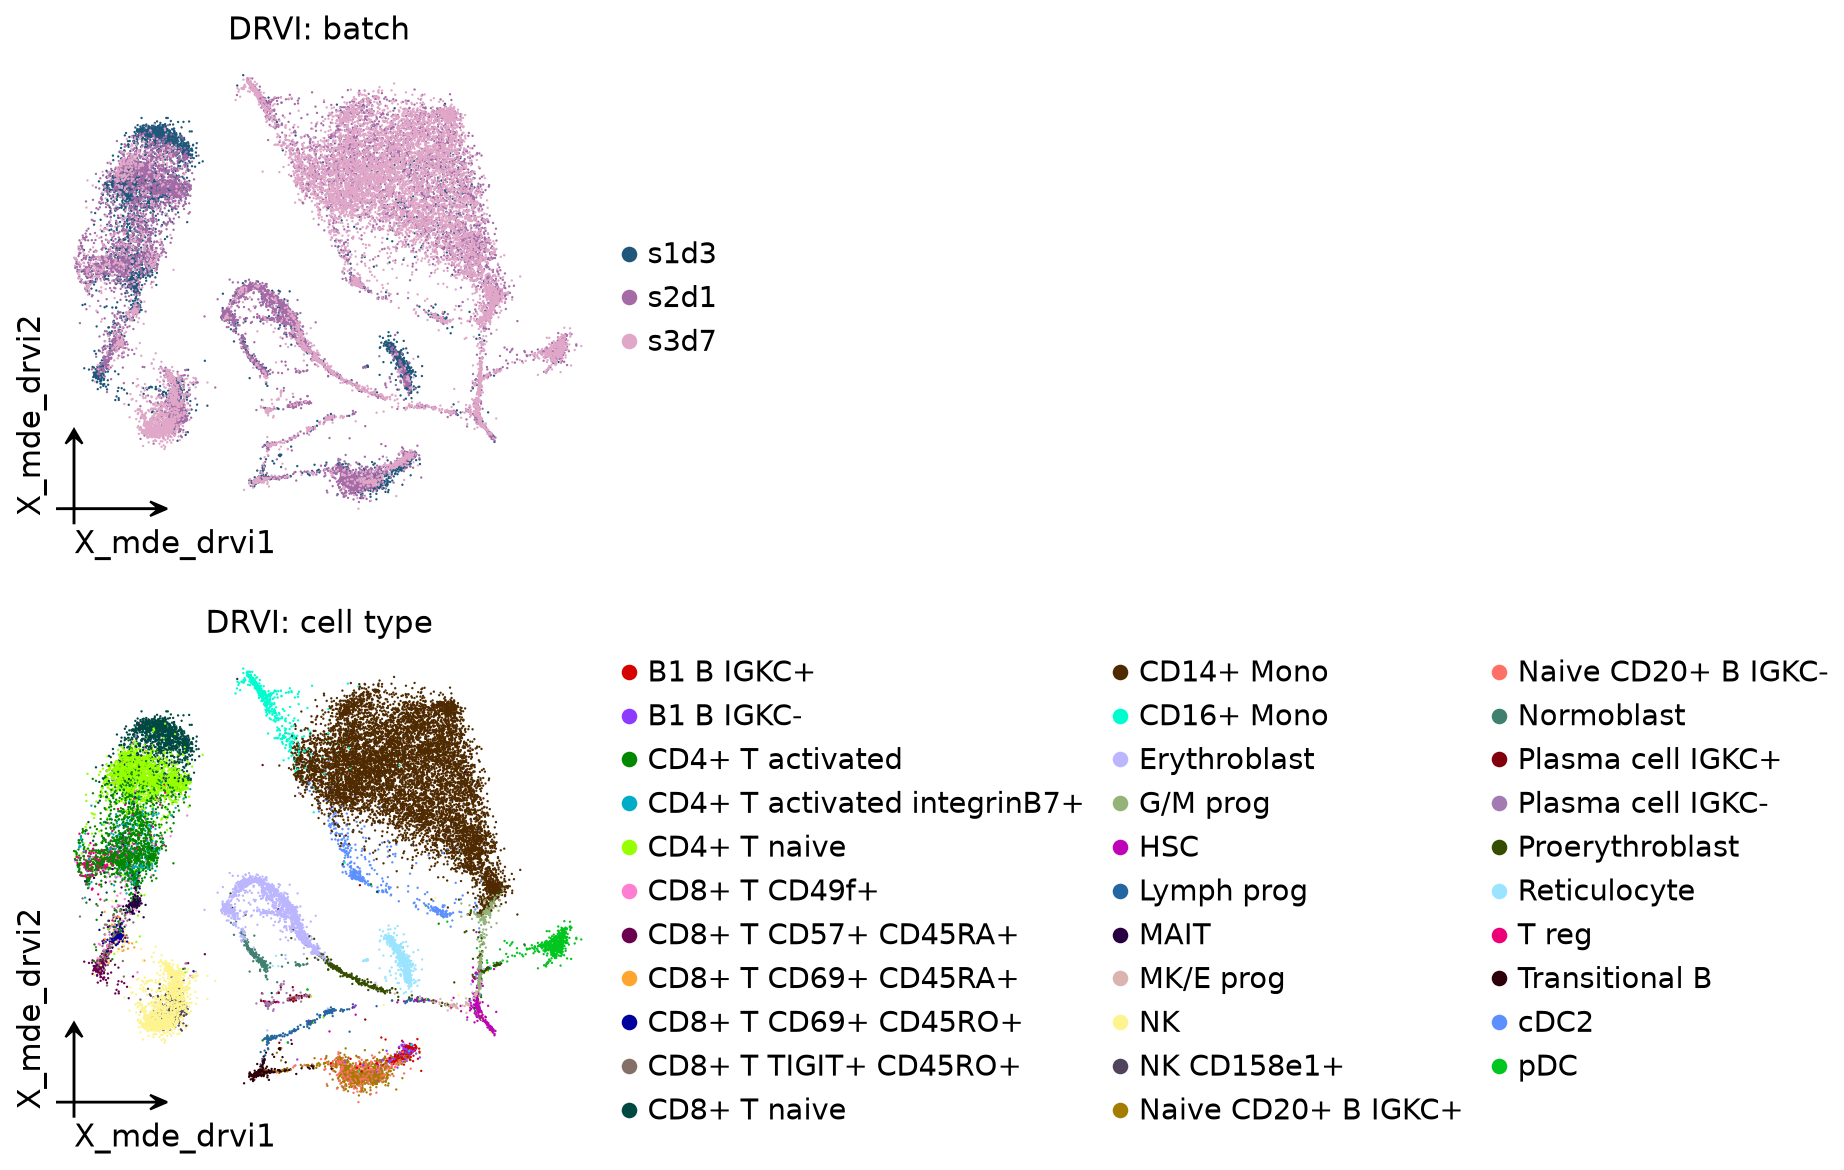

In [12]:
ov.pl.embedding(adata, basis='X_mde_drvi', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65, title=['DRVI: batch', 'DRVI: cell type'])


PCA shows the three donors as largely separate islands, consistent with the
crosstab above: `s1d3` is the outlier in composition (far fewer CD14+
monocytes than the other two: 309 vs. 2 958 / 6 056) as well as in sequencing
batch. DRVI pulls the large myeloid and lymphoid compartments (CD14+/CD16+
Mono, CD4+ T naive/activated) together across donors, and lays out the
erythroid lineage as a visible continuum (HSC → G/M / MK/E prog →
Proerythroblast → Normoblast → Reticulocyte) rather than three disjoint
donor blobs. Mixing is not perfect, though: `s1d3` — the smallest donor and
the most compositionally different — keeps a partly separate island (top
left) and a distinct sliver within the CD8+ T compartment. That is not a bug
in this run: the validation benchmark (`benchmarks/vi/results_drvi.md`)
reports the same, modest-not-complete batch mixing on this exact dataset
(iLISI ≈ 0.33 for both the native port and `drvi-py`) — DRVI's architecture
prioritises keeping every latent dimension's effect additive and
interpretable, which is a different trade-off than scVI's decoder, which is
free to use the batch covariate however it likes to remove batch effect.


In [13]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_drvi'], batch_key='batch',
                                   label_key='cell_type', n_jobs=4, subsample=8000)
scores.round(3)


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


           iLISI   kBET  ASW_batch  cLISI  ASW_label    NMI    ARI  graph_conn
embedding                                                                     
X_pca      0.012  0.333      0.582  1.000      0.589  0.773  0.598       0.799
X_drvi     0.382  0.671      0.813  0.997      0.552  0.783  0.752       0.819

| embedding | iLISI | kBET | ASW_batch | cLISI | ASW_label | NMI | ARI | graph_conn |
|---|---|---|---|---|---|---|---|---|
| `X_pca`  | 0.012 | 0.333 | 0.582 | 1.000 | 0.589 | 0.773 | 0.598 | 0.799 |
| `X_drvi` | 0.382 | 0.671 | 0.813 | 0.997 | 0.552 | 0.783 | 0.752 | 0.819 |

All three batch-removal metrics improve sharply (iLISI ×32, kBET ×2,
ASW_batch +0.23), while the bio-conservation metrics are essentially
unchanged (cLISI 1.000 → 0.997, ASW_label 0.589 → 0.552) or improve (NMI
0.773 → 0.783, ARI 0.598 → 0.752, graph_conn 0.799 → 0.819) — batch mixing is
bought without damaging cell-type structure. These numbers are not directly
comparable to `benchmarks/vi/results_drvi.md` (that run uses the paper's own
HVG selection and no cell QC, and scores the full 26 997 cells, not an
8 000-cell subsample), but they land in the same range (benchmark: iLISI ≈
0.33, cLISI ≈ 0.999, NMI ≈ 0.79, ARI ≈ 0.76) — a useful sanity check that
this quick single-seed tutorial run is not an outlier.


## 4. What makes DRVI different: one latent dimension at a time

Because the decoder is additive, a *single* latent dimension can be
inspected on its own — unlike scVI, where the 30 dimensions jointly produce
each gene's logit through a shared MLP. Two views of that:

* **Per-dimension profile across cell types** — the group-mean of each
  dimension, z-scored across groups. A dimension that lights up sharply in
  one or a few cell types is tracking that type's identity; one that varies
  smoothly across several is more likely a continuum (differentiation,
  cell cycle...).
* **`model.differential_vars(dim)`** — the top genes whose decoded
  expression changes most between the `+` and `-` extremes of that
  dimension (`model.latent_traverse()` under the hood), which we can check
  against known markers.


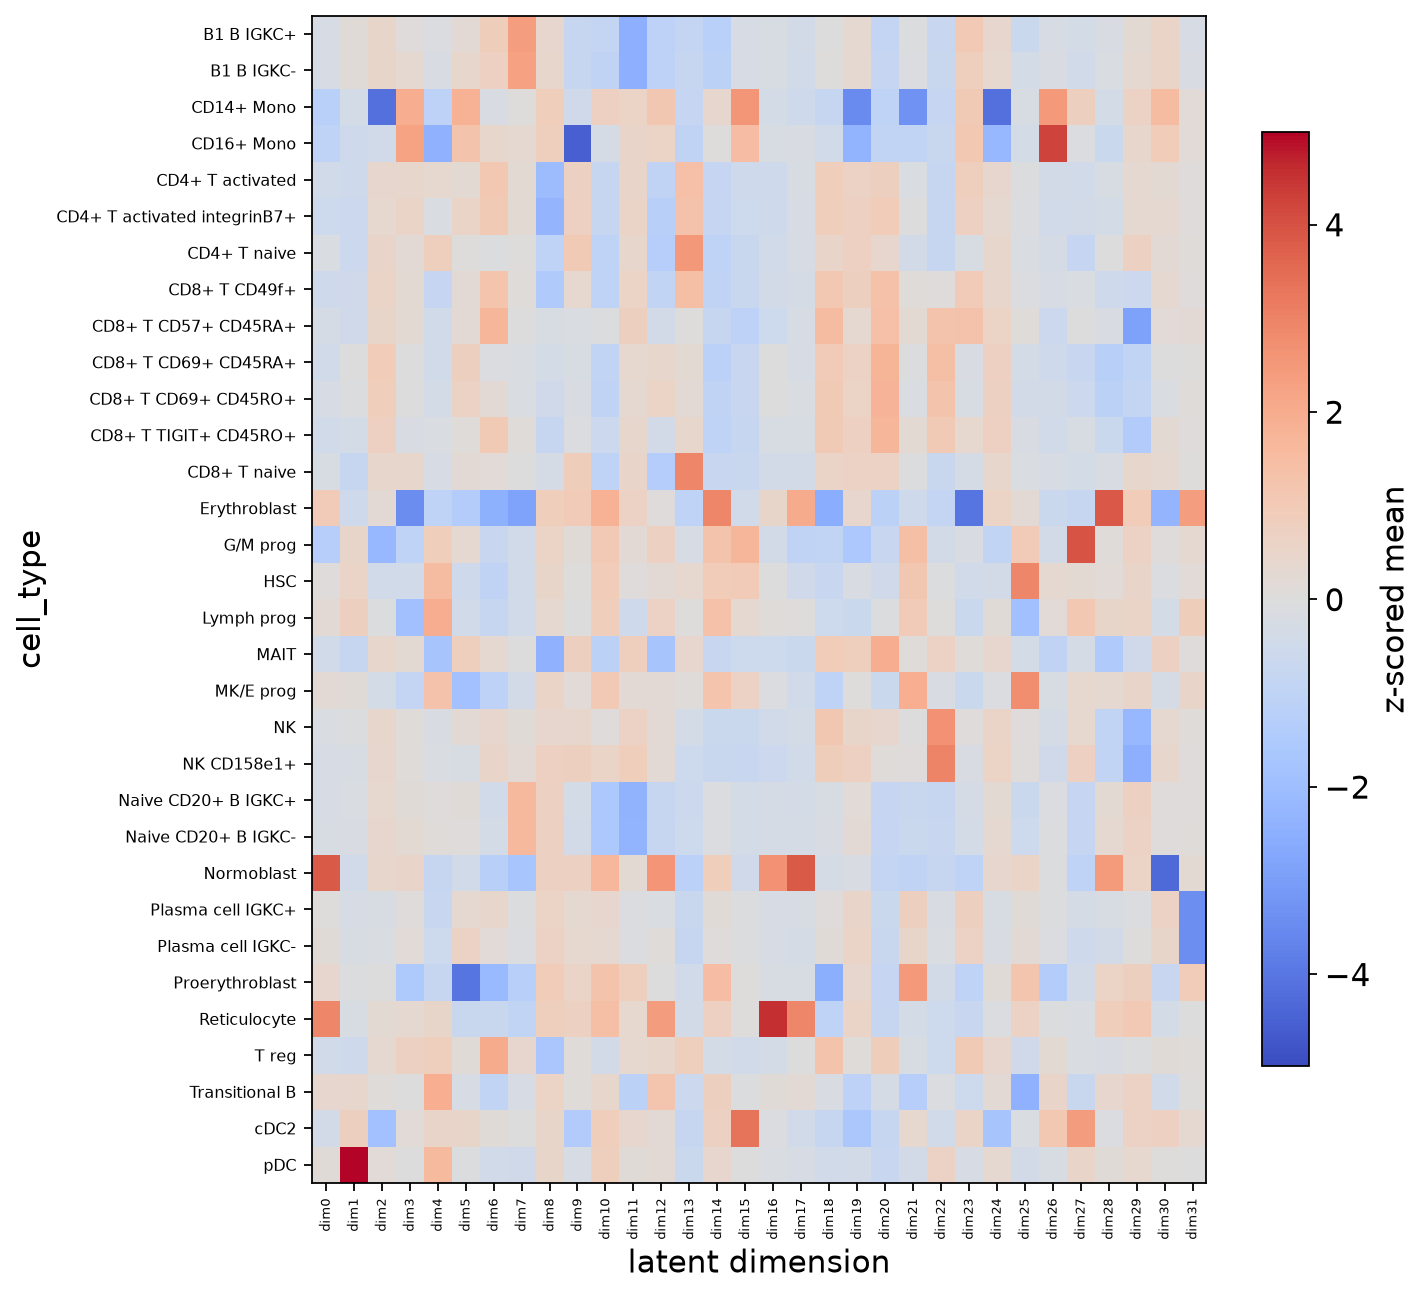

In [14]:
ax, dim_table = ov.vi.plot_dimension_heatmap(adata, 'X_drvi', groupby='cell_type')


A handful of dimensions stand out sharply against a single cell type rather
than varying smoothly across many — exactly what an *additive*,
per-dimension decoder should produce. The six dimensions with the largest
|z-score| anywhere in the table are `dim1` (**pDC**, z > 4), `dim2` (**CD14+
Mono**, negative), `dim9` (**CD16+ Mono**, negative), `dim16`
(**Reticulocyte**, z > 4), `dim26` (CD16+ Mono) and `dim30` (Normoblast,
negative). The erythroid lineage (HSC, G/M prog, Normoblast, Proerythroblast,
Reticulocyte rows) also shares several moderately-colored dimensions
(`dim3`, `dim4`, `dim23`) — consistent with it being a differentiation
continuum rather than a single discrete identity, so no one dimension should
own all of it.


In [15]:
top_dims = dim_table.abs().max(axis=0).sort_values(ascending=False).index[:6]
top_dims = [int(d.replace('dim', '')) for d in top_dims]
top_dims


[1, 16, 9, 30, 26, 2]

In [16]:
effects = model.dimension_gene_effects(n_genes=8, dims=top_dims)
gene_table = pd.DataFrame({f'dim{d} genes': effects[d][0] for d in top_dims})
gene_table


   dim1 genes dim16 genes dim9 genes dim30 genes dim26 genes dim2 genes
0       PTCRA      IFIT1B     FCGR3A  AC024267.1  AC005280.2         HP
1         SCT     RPL22L1       HES4       SPTA1        RBP7    S100A12
2      LILRA4        NME2       VMO1        SOX6      SMIM25        BPI
3       PTGDS       RNGTT     CDKN1C      SLC4A1        G0S2     S100A8
4        GZMB     ATP5IF1  LINC02432        RHAG    TMEM176B     CYP4F3
5       EPHB1       PSME2      MS4A7       TRAK2       HMOX1   SERPINB2
6      CLEC4C  AC007952.4      TPPP3       TSPO2    SERPINA1    TNFAIP6
7  AL591115.1  AC239799.2      SYT17      SLC2A1       PILRA  SERPINB10

Checked against established PBMC marker panels (the Azimuth human PBMC
reference, Hao *et al.* 2021; Villani *et al.* 2017 for the monocyte
subsets):

- **`dim1` (pDC)**: `PTCRA`, `SCT`, `LILRA4`, `PTGDS`, `GZMB`, `CLEC4C` — this
  *is* the canonical plasmacytoid dendritic cell signature (`LILRA4`/BDCA-4
  and `CLEC4C`/BDCA-2 are the standard pDC surface-marker genes; `PTCRA`,
  `PTGDS`, `SCT`, `GZMB` are the Azimuth reference's own top pDC markers).
  About as clean a hit as this kind of check gets.
- **`dim9` (CD16+ Mono)**: `FCGR3A` (the CD16 gene itself), `HES4`, `VMO1`,
  `CDKN1C`, `MS4A7` — the exact non-classical-monocyte gene set from Villani
  *et al.* and the Azimuth reference.
- **`dim2` (CD14+ Mono)**: `HP`, `S100A12`, `S100A8`, `BPI`, `TNFAIP6` —
  classical-monocyte / calprotectin genes, correctly on the myeloid branch
  even though the *sign* of the association is negative (this dimension's
  low values, not high ones, mark CD14+ Mono in the heatmap above).
- **`dim30` (Normoblast)**: `SPTA1`, `SLC4A1` (Band 3), `RHAG`, `TSPO2`,
  `SOX6`, `SLC2A1` (GLUT1) — a textbook late-erythroid membrane /
  erythropoiesis-transcription-factor signature.
- **`dim26`**: `TMEM176B`, `HMOX1`, `SERPINA1`, `PILRA`, `RBP7` — a second,
  less sharply-named myeloid program (markers reported for
  non-classical / anti-inflammatory monocyte states), distinct from the
  CD16-receptor dimension above.
- **`dim16` (Reticulocyte)** is the honest negative result: `IFIT1B`,
  `RPL22L1`, `NME2`, `RNGTT`, `ATP5IF1`, `PSME2` and two uncharacterised loci
  do not read as a clean reticulocyte signature — only `NME2` (reported to
  bind the γ-globin promoter) and the mitochondrial-clearance genes
  (`ATP5IF1`, `PSME2`, plausible given reticulocytes actively degrade
  organelles) have any documented connection to erythroid biology. Not every
  disentangled dimension corresponds to a crisp, literature-backed program —
  some capture technical covariates (RNA content, library complexity) that
  happen to track a cell type without being "about" its biology.


### Latent traversal

`model.latent_traverse()` is the primitive behind both tables above: for
each dimension it decodes `n_samples` random baselines with that one
dimension pinned to `+span` and to `-span` (everything else resampled from
the prior) and returns the mean log-fold-change per gene. Plotting the
genes most affected by the single most cell-type-specific dimension found
above, signed by the direction of the effect:


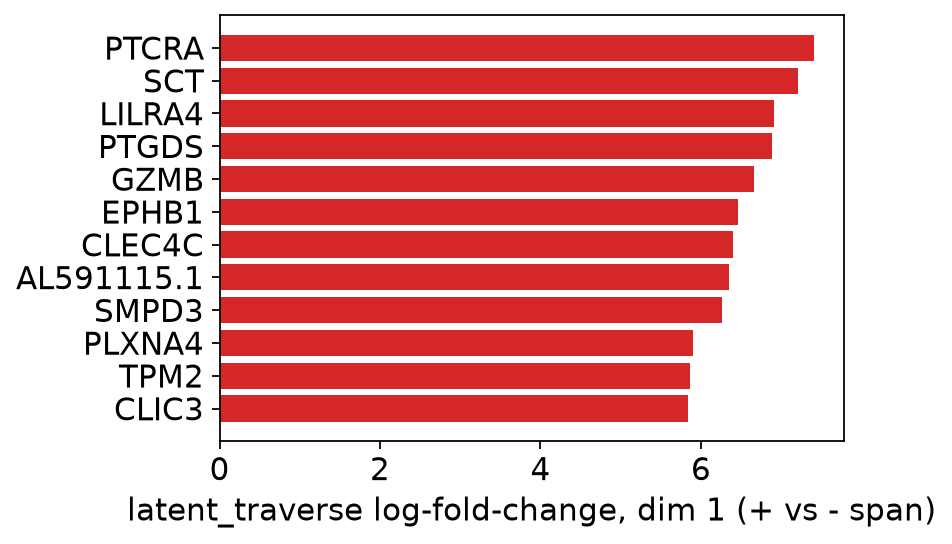

In [17]:
import matplotlib.pyplot as plt
genes_d, effect_d = model.differential_vars(dim=top_dims[0], n_genes=12)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.barh(genes_d[::-1], effect_d[::-1], color=np.where(effect_d[::-1] > 0, '#d62728', '#1f77b4'))
ax.set_xlabel(f'latent_traverse log-fold-change, dim {top_dims[0]} (+ vs - span)');


The traversal confirms the dimension-1 → pDC call with still more of the
same signature once the gene list is extended to 12: `SMPD3` now joins
`LILRA4` / `CLEC4C` / `PTCRA` — `LILRA4`, `CLEC4C` and `SMPD3` are reported
together as the Azimuth reference's top-3 pDC markers. Every one of the 12
genes moves in the *same* direction (all red / positive), which is the
additive-decoder signature at work: dimension 1 turns a single coherent gene
program up or down as a block, rather than trading some genes off against
others the way a shared, non-separable decoder would.


## 5. The same model trained from disk (AnnDataOOM)

`ov.read(path, storage='disk')` returns an **AnnDataOOM**: `obs` / `var` are
in memory, the count matrix stays in the `.h5ad` file. `ov.vi.DRVI` streams
the training genes of row blocks from the file with anndataoom-fast's
`pread` reader (no HDF5 library calls on the data path), block-shuffles them
through a bounded buffer, and sends them to the GPU — the host process
never holds the full matrix. This — training directly from disk, with no
scvi-tools dependency — is the point of `ov.vi`.


In [18]:
ov.settings.cpu_gpu_mixed_init()
adata_disk = ov.read(h5ad_path, storage='disk')
adata_disk = ov.pp.qc(adata_disk, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250}, doublets=False)
adata_disk = ov.pp.preprocess(adata_disk, mode='shiftlog|pearson', n_HVGs=2000)
type(adata_disk.layers['counts'])


CPU-GPU mixed mode activated
Available GPU accelerators: CUDA
📂 Reading with anndata-rs (Rust · out-of-memory)
   neurips2021_bmmc_counts.h5ad  (298.4 MB)
   ✓ Loaded in 0.09s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise
🖥️ Using CPU mode for QC (out-of-memory)...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ H


   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range (Min - Max)       │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ nUMIs                   │ 5197               │ 742 - 32877             │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Detected Genes          │ 1339               │ 103 - 5543              │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Mitochondrial %         │ 6.6%               │ 0.0% - 23.0%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Ribosomal %             │ 24.6%              │ 0.1% - 69.4%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Hemoglobin %            │ 9.7%               │ 0.0% - 96.1%            │
   └─────────────────────────┴────────

    Time to analyze data (out-of-memory): 0.40 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson


anndataoom._core._SubsetBackedArray

In [19]:
model_disk = ov.vi.DRVI(adata_disk, layer='counts', batch_key='batch',
                        genes='highly_variable_features', n_latent=32)
with ov.vi.MemoryMonitor() as mon_disk:
    model_disk.train(max_epochs=100, batch_size=128, check_val_every_n_epoch=10)
mon_disk


Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

MemoryMonitor(wall 29.6 s, RSS 7.96 -> peak 8.04 GB (+0.08), GPU used peak 3.72 GB)

In [20]:
pd.DataFrame({'in memory': {'elbo_train': model.history_['elbo_train'][-1], **mon_mem.summary()},
              'disk (AnnDataOOM)': {'elbo_train': model_disk.history_['elbo_train'][-1], **mon_disk.summary()}}).T.round(3)


                   elbo_train  wall_s  rss_start_gb  rss_peak_gb  \
in memory            1292.618  27.049         2.137        2.978   
disk (AnnDataOOM)    1295.509  29.607         7.964        8.045   

                   rss_growth_gb  gpu_peak_gb  
in memory                  0.841        2.098  
disk (AnnDataOOM)          0.080        3.721  

`elbo_train` after 100 epochs: 1292.6 (in memory) vs. 1295.5 (AnnDataOOM) —
within 0.2% of each other, confirming disk-backed training reads the correct
rows and genes and reaches the same optimum as in-memory training (these
absolute numbers are *not* comparable to `benchmarks/vi/results_drvi.md`'s
≈810: that benchmark uses the paper's own seurat_v3 HVG selection on
unfiltered cells, a different gene set with a different count scale — the
relevant check here is memory ≈ disk within this run, not the absolute
value). `rss_growth_gb` is small either way (+0.84 GB / +0.08 GB) because
this notebook's dataset comfortably fits in host memory; the benefit of
`storage='disk'` shows up on data that does not.


In [21]:
ov.settings.cpu_init()   # back to the default mode


CPU mode activated


## Key parameters

```python
ov.vi.DRVI(adata, layer=None, batch_key=None, labels_key=None,
          categorical_covariate_keys=None, continuous_covariate_keys=None, genes=None,
          n_hidden=128, n_layers=2, n_latent=32,
          n_split_latent=-1, split_aggregation='logsumexp',
          dispersion='gene', gene_likelihood='pnb',
          dropout_rate=0.0, encoder_dropout_rate=0.1,
          encode_covariates=False, deeply_inject_covariates=False, seed=0)
```

- `n_split_latent=-1` / `split_aggregation='logsumexp'`: the disentangling
  choice — one decoder view per latent dimension, combined additively in
  probability space. `'sum'` / `'max'` aggregation and fewer splits are also
  available but are not the paper's setting.
- `gene_likelihood`: `'pnb'` (default, `drvi-py`'s own), `'nb'`, `'poisson'`
  (all three `drvi-py`'s), or `'zinb'` (added here, not in `drvi-py` / not
  covered by the parity benchmark).
- `ov.single.drvi(adata, layer='counts', batch_key='batch', n_latent=32)` is
  a one-line wrapper: trains the model and writes `adata.obsm['X_drvi']`,
  returning the fitted model for `.differential_vars` / `.latent_traverse`.
- Interpretability: `model.latent_traverse(span=5.0, n_samples=200, dims=None)`,
  `model.differential_vars(dim, n_genes=20)`,
  `model.dimension_gene_effects(n_genes=20, dims=None)`.

## Related tutorials

- [../t_vi](../t_vi.ipynb) — `ov.vi.SCVI` / `SCANVI` / `TOTALVI`: in memory,
  disk-backed, GPU-mode Dask training, multi-GPU, label transfer.
- [t_batch_scvi](t_batch_scvi.ipynb) — scVI through the
  `ov.single.batch_correction` dispatcher.

For the benchmark this tutorial's numbers are checked against (ELBO,
disentanglement scores, scib metrics, native vs. `drvi-py` parity), see
`benchmarks/vi/results_drvi.md` in the omicverse repository.
